Winning WHERE In The Trenches?

Can NFL teams power their run game behind athletic offensive lines alone? I compared speed and acceleration from pass-protection and pulling drills against NFL pressure rates and rushing outcomes for offensive linemen from the 2023–2025 draft classes.

In [13]:
# Load the datasets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

players = pd.read_csv('/content/players.csv')
combine = pd.read_csv('/content/combine_results.csv')
combine_tracking = pd.read_csv('/content/combine_tracking.csv')
player_play = pd.read_csv('/content/player_play.csv')

In [14]:
# Calculate offensive-line Combine movement metrics

ol_ids = players.loc[
    players['nfl_position'].isin(['T', 'G', 'C']), 'nfl_id'
]

ol_tracking = combine_tracking[
    (combine_tracking['nfl_id'].isin(ol_ids)) &
    (combine_tracking['entity_type'] == 'PLAYER')
].copy()

# Standardize drill names across years
ol_tracking['drill_name'] = ol_tracking['drill_name'].replace({
    'PASS_PRO-MIRROR_DRILL': 'PASS_PRO_MIRROR_DRILL'
})

drills = [
    'PASS_PRO_MIRROR_DRILL',
    'OL_PULL_DRILL_FOLD_BLOCK_RIGHT'
]

ol_tracking = ol_tracking[
    ol_tracking['drill_name'].isin(drills)
]

# Measure movement within each attempt
attempt_metrics = (
    ol_tracking.groupby(['nfl_id', 'drill_name', 'event_id', 'attempt'])
    .agg(
        speed_95=('s', lambda x: x.quantile(0.95)),
        acceleration_95=('a', lambda x: x.quantile(0.95))
    )
    .reset_index()
)

# Get each player's typical performance across attempts
drill_metrics = (
    attempt_metrics.groupby(['nfl_id', 'drill_name'])
    [['speed_95', 'acceleration_95']]
    .median()
    .reset_index()
)

print(drill_metrics.groupby('drill_name')['nfl_id'].nunique())

drill_name
OL_PULL_DRILL_FOLD_BLOCK_RIGHT    119
PASS_PRO_MIRROR_DRILL             121
Name: nfl_id, dtype: int64


In [15]:
# Calculate NFL pass-protection performance

ol_pass = player_play[
    (player_play['nfl_id'].isin(ol_ids)) &
    (player_play['pressure_allowed'].notna()) &
    (player_play['play_nullified_by_penalty'] == 'N') &
    (player_play['team_abbr'] == player_play['possession_team'])
].copy()

ol_pass['pressure_flag'] = ol_pass['pressure_allowed'].eq(True).astype(int)

pass_metrics = (
    ol_pass.groupby('nfl_id')
    .agg(
        pass_snaps=('pressure_flag', 'size'),
        pressures_allowed=('pressure_flag', 'sum'),
        pressure_rate=('pressure_flag', 'mean')
    )
    .reset_index()
)

# Exclude players with fewer than 100 recorded opportunities
pass_metrics = pass_metrics[pass_metrics['pass_snaps'] >= 100]

print("Players eligible for analysis:", len(pass_metrics))
print(pass_metrics[['pass_snaps', 'pressure_rate']].describe().round(3))

Players eligible for analysis: 89
       pass_snaps  pressure_rate
count      89.000         89.000
mean      658.753          0.081
std       521.725          0.025
min       104.000          0.018
25%       215.000          0.066
50%       574.000          0.078
75%       905.000          0.099
max      2103.000          0.145


In [16]:
# Calculate rushing performance on plays involving each lineman

run_pattern = r'\b(?:left|right) (?:end|tackle|guard)\b|\bup the middle\b'

ol_runs = player_play[
    (player_play['nfl_id'].isin(ol_ids)) &
    (player_play['team_abbr'] == player_play['possession_team']) &
    (player_play['play_nullified_by_penalty'] == 'N') &
    (player_play['play_description'].str.contains(
        run_pattern, case=False, na=False
    )) &
    (~player_play['play_description'].str.contains(
        r'\b(?:pass|sack|scrambl)\w*\b', case=False, na=False
    ))
].drop_duplicates(['nfl_id', 'game_id', 'play_id'])

run_metrics = (
    ol_runs.groupby('nfl_id')
    .agg(
        run_plays=('play_id', 'size'),
        avg_rush_yards=('yards_gained', 'mean'),
        avg_rush_epa=('expected_points_added', 'mean')
    )
    .reset_index()
)

run_metrics = run_metrics[run_metrics['run_plays'] >= 100]

print("Players eligible for rushing analysis:", len(run_metrics))
print(run_metrics[['run_plays', 'avg_rush_yards', 'avg_rush_epa']].describe().round(3))

Players eligible for rushing analysis: 76
       run_plays  avg_rush_yards  avg_rush_epa
count     76.000          76.000        76.000
mean     498.092           4.108        -0.097
std      348.597           0.444         0.073
min      101.000           2.772        -0.290
25%      202.250           3.816        -0.137
50%      421.500           4.158        -0.095
75%      689.000           4.379        -0.051
max     1561.000           5.360         0.048


In [17]:
# Combine athleticism and NFL performance into one dataset

drill_wide = drill_metrics.pivot(
    index='nfl_id',
    columns='drill_name',
    values=['speed_95', 'acceleration_95']
)

drill_wide.columns = [
    f"{metric}_{'mirror' if drill == 'PASS_PRO_MIRROR_DRILL' else 'pull'}"
    for metric, drill in drill_wide.columns
]

drill_wide = drill_wide.reset_index()

analysis = (
    players[players['nfl_position'].isin(['T', 'G', 'C'])]
    [['nfl_id', 'display_name', 'draft_year', 'nfl_position']]
    .merge(
        combine[['nfl_id', 'ten_yd_split',
                 'short_shuttle', 'ngs_athleticism_score']],
        on='nfl_id', how='left'
    )
    .merge(drill_wide, on='nfl_id', how='left')
    .merge(pass_metrics, on='nfl_id', how='left')
    .merge(run_metrics, on='nfl_id', how='left')
)

print("Players in combined dataset:", len(analysis))

print("\nAvailable measurements:")
print(analysis[[
    'pressure_rate',
    'avg_rush_yards',
    'speed_95_mirror',
    'acceleration_95_mirror',
    'speed_95_pull',
    'acceleration_95_pull',
    'ten_yd_split',
    'short_shuttle',
    'ngs_athleticism_score'
]].notna().sum())

Players in combined dataset: 121

Available measurements:
pressure_rate              89
avg_rush_yards             76
speed_95_mirror           121
acceleration_95_mirror    121
speed_95_pull             119
acceleration_95_pull      119
ten_yd_split               96
short_shuttle              64
ngs_athleticism_score     121
dtype: int64


In [18]:
# Compare Combine measurements with NFL performance

features = [
    'speed_95_mirror',
    'acceleration_95_mirror',
    'speed_95_pull',
    'acceleration_95_pull',
    'ten_yd_split',
    'short_shuttle',
    'ngs_athleticism_score'
]

outcomes = ['pressure_rate', 'avg_rush_yards', 'avg_rush_epa']

results = []

for outcome in outcomes:
    for feature in features:
        data = analysis[[feature, outcome]].dropna()

        results.append({
            'outcome': outcome,
            'feature': feature,
            'players': len(data),
            'correlation': data[feature].corr(
                data[outcome], method='spearman'
            )
        })

correlations = pd.DataFrame(results)

print(correlations.round(3).to_string(index=False))

       outcome                feature  players  correlation
 pressure_rate        speed_95_mirror       89        0.068
 pressure_rate acceleration_95_mirror       89       -0.103
 pressure_rate          speed_95_pull       87       -0.119
 pressure_rate   acceleration_95_pull       87        0.051
 pressure_rate           ten_yd_split       72       -0.062
 pressure_rate          short_shuttle       47        0.105
 pressure_rate  ngs_athleticism_score       89       -0.081
avg_rush_yards        speed_95_mirror       76        0.250
avg_rush_yards acceleration_95_mirror       76        0.163
avg_rush_yards          speed_95_pull       75        0.114
avg_rush_yards   acceleration_95_pull       75       -0.200
avg_rush_yards           ten_yd_split       63       -0.262
avg_rush_yards          short_shuttle       40        0.057
avg_rush_yards  ngs_athleticism_score       76        0.127
  avg_rush_epa        speed_95_mirror       76        0.112
  avg_rush_epa acceleration_95_mirror   

In [22]:
# Evaluate whether drill tracking adds predictive value

from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor

tracking_features = [
    'speed_95_mirror', 'acceleration_95_mirror',
    'speed_95_pull', 'acceleration_95_pull'
]

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))

results = []

for outcome in ['pressure_rate', 'avg_rush_yards', 'avg_rush_epa']:
    data = analysis[
        ['draft_year', 'nfl_position', 'ngs_athleticism_score',
         *tracking_features, outcome]
    ].dropna()

    controls = pd.get_dummies(
        data[['draft_year', 'nfl_position']].astype(str),
        drop_first=True, dtype=int
    )

    baseline = pd.concat(
        [controls, data[['ngs_athleticism_score']]], axis=1
    )
    combined = pd.concat([baseline, data[tracking_features]], axis=1)

    for name, estimator, X in [
        ('Mean Only', DummyRegressor(), baseline),
        ('Combine Score', ridge, baseline),
        ('Score + Tracking', ridge, combined)
    ]:
        mae = -cross_val_score(
            estimator, X, data[outcome],
            cv=cv, scoring='neg_mean_absolute_error'
        ).mean()

        results.append([outcome, name, mae, len(data)])

model_results = pd.DataFrame(
    results, columns=['Outcome', 'Model', 'MAE', 'Players']
)

print(
    model_results.pivot(
        index='Outcome', columns='Model', values='MAE'
    ).round(4)
)

Model           Combine Score  Mean Only  Score + Tracking
Outcome                                                   
avg_rush_epa           0.0612     0.0581            0.0607
avg_rush_yards         0.3589     0.3543            0.3546
pressure_rate          0.0170     0.0200            0.0172


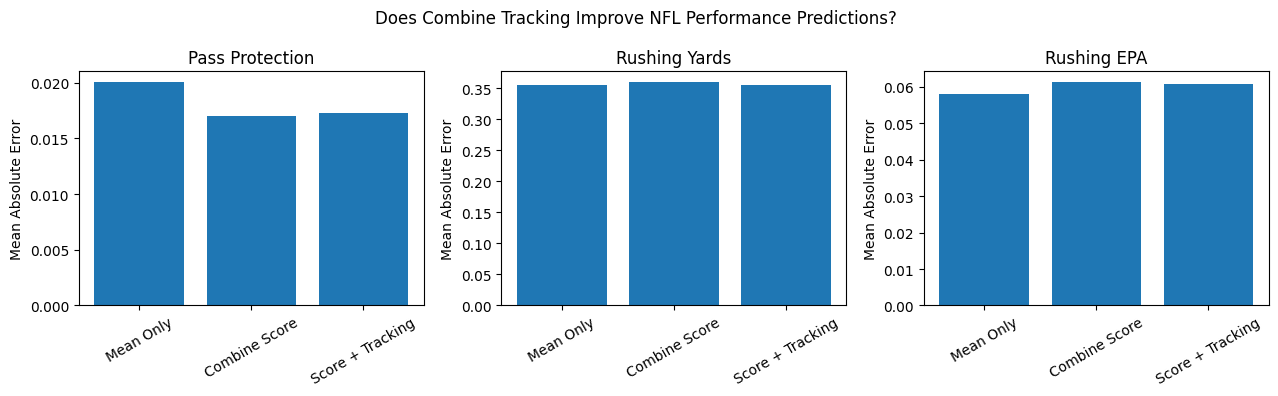

In [23]:
# Visualize model prediction accuracy

outcome_labels = {
    'pressure_rate': 'Pass Protection',
    'avg_rush_yards': 'Rushing Yards',
    'avg_rush_epa': 'Rushing EPA'
}

model_order = ['Mean Only', 'Combine Score', 'Score + Tracking']

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (outcome, title) in zip(axes, outcome_labels.items()):
    scores = (
        model_results[model_results['Outcome'] == outcome]
        .set_index('Model')
        .reindex(model_order)
    )

    ax.bar(model_order, scores['MAE'])
    ax.set_title(title)
    ax.set_ylabel('Mean Absolute Error')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Does Combine Tracking Improve NFL Performance Predictions?')
plt.tight_layout()
plt.show()

Next steps would be to include metrics like first-step quickness, lateral movement, and change-of-direction efficiency.